Run EDA for test year's data:

In [36]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import eda_copy
import eda
import matplotlib.pyplot as plt

In [37]:
# load test items
TRAIN_YEAR, TEST_YEAR = 2009, 2011
data = np.load(f'{TRAIN_YEAR}train_{TEST_YEAR}test_items.npz')
items = data['test_items']

SALARY_CAP = {2000: 34.0, 2001: 35.5, 2002: 42.5, 2003: 40.3, 2004: 43.9, 2005: 43.9, 2006: 49.5,
              2007: 53.1, 2008: 55.6, 2009: 58.7, 2010: 57.7, 2011: 58.0, 2012: 58.0, 2013: 58.7,
              2014: 58.7, 2015: 63.1, 2016: 70.0, 2017: 94.1, 2018: 99.1, 2019: 101.9, 2020: 109.1,
              2021: 109.1, 2022: 112.4, 2023: 123.7, 2024: 136.0, 2025: 140.6}
capacity = SALARY_CAP[TEST_YEAR]
n_selected = 10
n_con = 1
n_obj = items.shape[1] - n_con
pop_size = 1_000
generations = 150 
max_no_improve_gen = 3
max_row_diff = 0.05 # fraction of the number of Pareto front (depends on number of objectives)
seed = 1123 + TEST_YEAR

In [38]:
# load 
probabilities = np.load(f'{TRAIN_YEAR}train_{TEST_YEAR}test_p.npz')
p = probabilities['pred_test_p']
p_true = probabilities['test_p']

In [ ]:
import matplotlib.pyplot as plt
plt.plot(p)
plt.show()

In [ ]:
plt.plot(p_true)
plt.show()

In [ ]:
# run EDA
eda_run = eda_copy.KnapsackEDA(
    items=items,
    capacity=capacity,
    n_selected=n_selected,
    n_obj=n_obj,
    pop_size=1000,
    generations=200,
    max_no_improve_gen=3,
    max_row_diff=0.1,
    seed=seed,
    distribution=None
)
results = eda_run.run()

import pickle
with open(f"generalize/mode1_eda_nba_{seed}seed.pkl", "wb") as f:
    pickle.dump(results, f)

Mode 1 generation 1 (no improve count: 0)
Mode 1 generation 2 (no improve count: 0)
Mode 1 generation 3 (no improve count: 0)
Mode 1 generation 4 (no improve count: 0)
Mode 1 generation 5 (no improve count: 0)
Mode 1 generation 6 (no improve count: 0)
Mode 1 generation 7 (no improve count: 0)
Mode 1 generation 8 (no improve count: 0)
Mode 1 generation 9 (no improve count: 0)
Mode 1 generation 10 (no improve count: 0)
Mode 1 generation 11 (no improve count: 0)
Mode 1 generation 12 (no improve count: 0)
Mode 1 generation 13 (no improve count: 1)
Mode 1 generation 14 (no improve count: 0)
Mode 1 generation 15 (no improve count: 0)
Mode 1 generation 16 (no improve count: 0)
Mode 1 generation 17 (no improve count: 0)
Mode 1 generation 18 (no improve count: 0)
Mode 1 generation 19 (no improve count: 0)
Mode 1 generation 20 (no improve count: 1)
Mode 1 generation 21 (no improve count: 2)
EDA finished in 9.53s (mode 1: 21 gens)


In [ ]:
import matplotlib.pyplot as plt

js_div_list = results["js_div_list"]
plt.plot(js_div_list)
plt.show()


In [5]:
with open(f"generalize/original_eda_nba_{seed}seed.pkl", "rb") as f:
    results_true = pickle.load(f)
with open(f"generalize/eda_nba_{seed}seed.pkl", "rb") as f:
    results = pickle.load(f)
with open(f"generalize/mode2_eda_nba_{seed}seed.pkl", "rb") as f:
    results_mode2 = pickle.load(f)
with open(f"generalize/mode1_eda_nba_{seed}seed.pkl", "rb") as f:
    results_mode1 = pickle.load(f)

In [7]:
pf = results["converged_pf_table"][-1]
pf_true = results_true["converged_pf_table"][-1]
pf_mode2 = results_mode2["converged_pf_table"][-1]
pf_mode1 = results_mode1["pareto_front_table"][-1]
objective_names = ['PTS', 'TRB', 'AST', 'STL', 'BLK']

In [8]:
pf.shape

(7054, 5)

In [9]:
pf_true.shape

(6748, 5)

In [10]:
pf_mode2.shape

(6918, 5)

In [11]:
pf_mode1.shape

(538, 6)

In [22]:
print(results["elapsed_sec"])
print(results_true["elapsed_sec"])
print(results_mode2["elapsed_sec"])
print(results_mode1["elapsed_sec"])

24.53873361647129
31.861619787290692
24.619775539264083
9.525968907400966


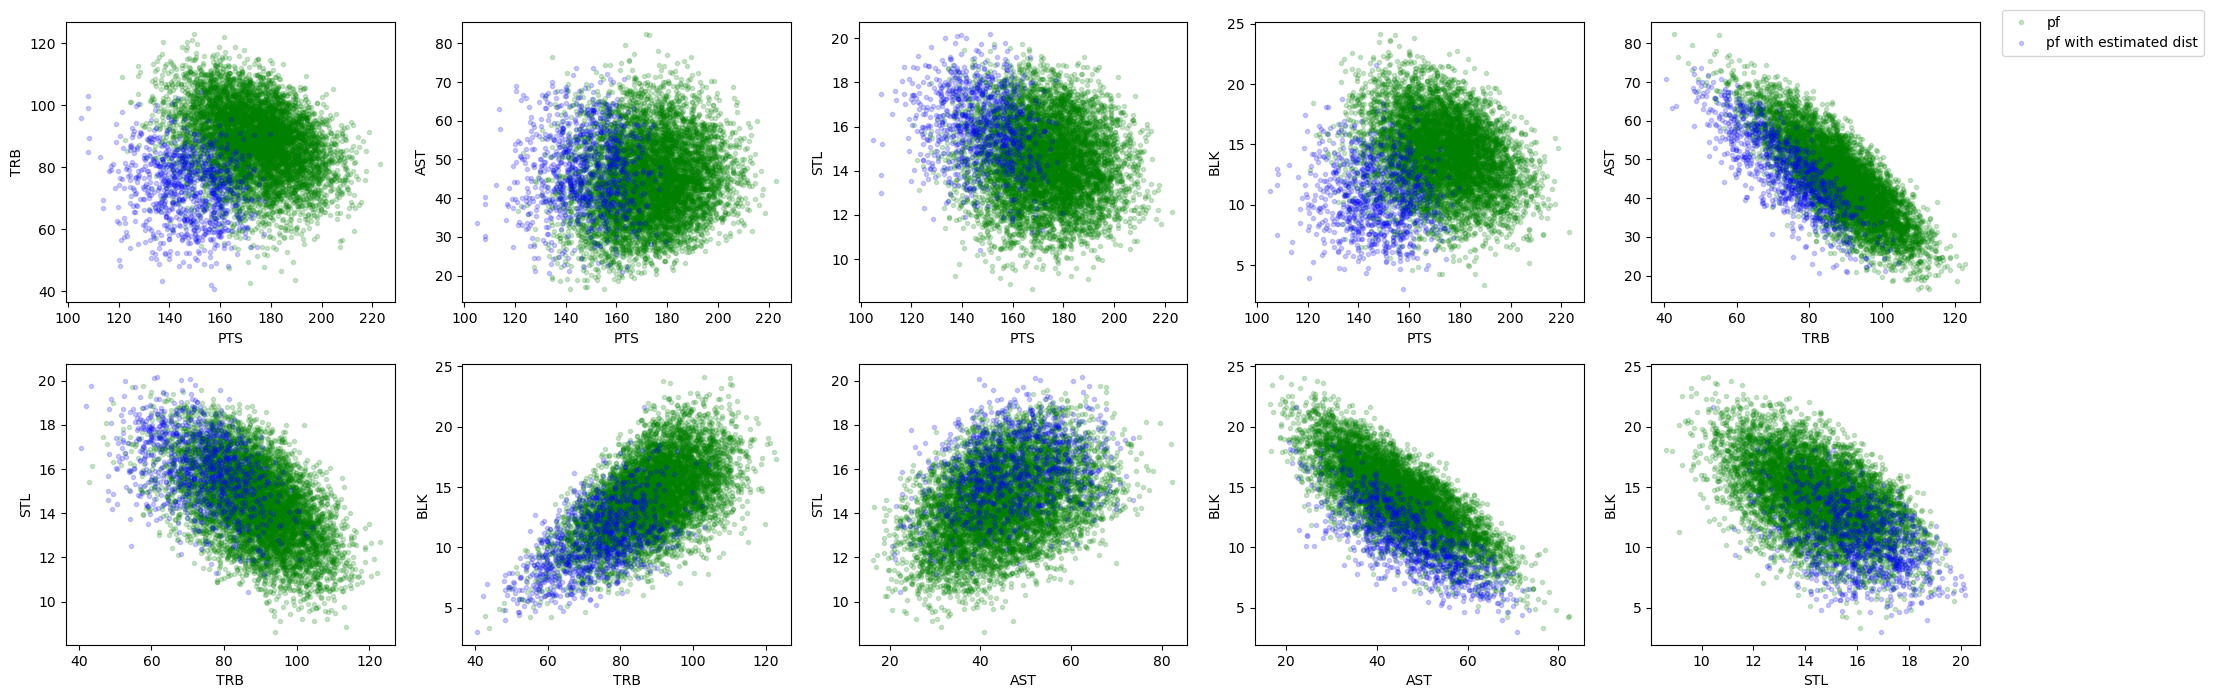

In [34]:
import math
import itertools

objective_pairs = list(itertools.combinations(range(n_obj), 2))
n_plots = len(objective_pairs)
cols = min(5, n_plots)
rows = math.ceil(n_plots / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.atleast_1d(axes).ravel()
for ax, (a, b) in zip(axes, objective_pairs):
    ax.plot(pf_true[:, a], pf_true[:, b], "go", alpha=0.2, markersize=3, label="pf")
    ax.plot(pf_sampled[:, a], pf_sampled[:, b], "bo", alpha=0.2, markersize=3, label="pf with estimated dist")
    # ax.plot(pf[:, a], pf[:, b], "bo", alpha=0.2, markersize=3, label="pf with estimated dist")
    # ax.plot(pf_mode2[:, a], pf_mode2[:, b], "ro", alpha=0.2, markersize=3, label="pf mode 2")
    # ax.plot(
    #     pf_mode1[:, a], pf_mode1[:, b], "o",
    #     markerfacecolor="none", markeredgecolor="black",
    #     alpha=0.2, markersize=3, label="pf mode 1",
    # )
    ax.set_xlabel(objective_names[a])
    ax.set_ylabel(objective_names[b])

for ax in axes[n_plots:]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper left",
    bbox_to_anchor=(1.0, 1.0),
)
fig.tight_layout()
plt.show()

In [18]:
def calculate_dominated(pf_predicted, pf_actual, n_obj):
    dominated = np.zeros(len(pf_predicted))
    for i in range(len(pf_predicted)):
        for j in range(len(pf_actual)):
            if np.all(pf_actual[j, :n_obj] >= pf_predicted[i, :n_obj]) and \
                np.any(pf_actual[j, :n_obj] > pf_predicted[i, :n_obj]):
                dominated[i] = 1
                break
    return np.sum(dominated), np.sum(dominated)/len(pf_predicted)

num_dominated, ratio_dominated = calculate_dominated(pf_mode1, pf_true, 5)
print(ratio_dominated)

0.8605947955390335


In [24]:
print(calculate_dominated(pf_mode2, pf_true, 5))
print(calculate_dominated(pf_true, pf_mode2, 5))
print(calculate_dominated(pf, pf_true, 5))
print(calculate_dominated(pf_true, pf, 5))

(1145.0, 0.16551026308181555)
(1676.0, 0.24836988737403676)
(736.0, 0.10433796427558832)
(1780.0, 0.26378186129223474)


In [35]:
from eda_copy import sample_population, get_objectives, non_dominated
population = sample_population(
    items, 
    p, 
    10_000, 
    n_selected, 
    capacity, 
    rng=np.random.RandomState(seed)
)
objectives = get_objectives(items, population, n_obj)

ind_idx = non_dominated(objectives).astype(bool)
ps_sampled = population[ind_idx]
pf_sampled = objectives[ind_idx]

In [33]:
pf_sampled.shape

(856, 5)

In [30]:
print(calculate_dominated(pf_sampled, pf_true, 5))
print(calculate_dominated(pf_true, pf_sampled, 5))
print(calculate_dominated(pf_sampled, pf, 5))
print(calculate_dominated(pf, pf_sampled, 5))

(836.0, 0.9766355140186916)
(0.0, 0.0)
(850.0, 0.9929906542056075)
(0.0, 0.0)
